Processing subjects:  18%|█▊        | 12/68 [00:00<00:00, 70.00it/s]

Processing subject 055 ...
Processing subject 041 ...
Processing subject 039 ...
Processing subject 037 ...
Processing subject 212 ...
Processing subject 213 ...
Processing subject 216 ...
Processing subject 211 ...
Processing subject 218 ...
Processing subject 220 ...
Processing subject 219 ...


Processing subjects:  35%|███▌      | 24/68 [00:02<00:05,  7.67it/s]

Processing subject 221 ...
Subject 218: RESP channel not found.
Processing subject 222 ...
Subject 219: RESP channel not found.
Processing subject 224 ...
Subject 041 processed with 49 valid windows.
Subject 037 processed with 47 valid windows.
Subject 055 processed with 49 valid windows.
Processing subject 225 ...
Processing subject 226 ...
Processing subject 230 ...
Subject 220 processed with 47 valid windows.
Subject 211 processed with 49 valid windows.
Processing subject 231 ...
Subject 039 processed with 48 valid windows.
Processing subject 237 ...
Processing subject 240 ...
Subject 212 processed with 48 valid windows.
Subject 216 processed with 45 valid windows.
Subject 222 processed with 49 valid windows.


Processing subjects:  53%|█████▎    | 36/68 [00:04<00:04,  7.49it/s]

Processing subject 248 ...
Subject 221 processed with 48 valid windows.
Subject 213 processed with 46 valid windows.
Processing subject 252 ...
Processing subject 253 ...
Processing subject 254 ...
Processing subject 260 ...
Subject 224 processed with 49 valid windows.
Processing subject 262 ...
Subject 226 processed with 45 valid windows.
Subject 262: RESP channel not found.
Processing subject 276 ...
Subject 230 processed with 48 valid windows.
Processing subject 281 ...
Subject 240 processed with 49 valid windows.
Processing subject 284 ...
Subject 237 processed with 48 valid windows.
Subject 225 processed with 47 valid windows.
Processing subject 291 ...
Processing subject 401 ...
Subject 276: RESP channel not found.
Processing subject 403 ...
Subject 231 processed with 49 valid windows.
Subject 281: RESP channel not found.
Processing subject 404 ...
Processing subject 405 ...


... (3 outputs left out)

Subject 248 processed with 49 valid windows.
Processing subject 409 ...
Subject 252 processed with 48 valid windows.
Processing subject 410 ...
Subject 260 processed with 48 valid windows.
Processing subject 411 ...
Subject 253 processed with 49 valid windows.
Subject 254 processed with 46 valid windows.
Processing subject 413 ...
Processing subject 414 ...
Subject 291 processed with 49 valid windows.
Processing subject 415 ...
Subject 401 processed with 47 valid windows.
Processing subject 417 ...
Subject 404 processed with 38 valid windows.
Processing subject 418 ...
Subject 284 processed with 49 valid windows.
Processing subject 427 ...
Subject 403 processed with 49 valid windows.
Processing subject 430 ...
Subject 410 processed with 45 valid windows.
Processing subject 437 ...


Processing subjects: 100%|██████████| 68/68 [00:06<00:00, 10.37it/s]

Subject 413 processed with 44 valid windows.
Processing subject 438 ...
Subject 409 processed with 46 valid windows.
Processing subject 439 ...
Subject 408 processed with 48 valid windows.
Subject 415 processed with 26 valid windows.
Processing subject 443 ...
Processing subject 442 ...


Subject 414 processed with 47 valid windows.
Subject 411 processed with 46 valid windows.
Processing subject 444 ...
Subject 417 processed with 35 valid windows.
Processing subject 446 ...
Processing subject 449 ...
Subject 418 processed with 45 valid windows.
Processing subject 451 ...
Subject 430 processed with 39 valid windows.
Subject 427 processed with 47 valid windows.
Processing subject 452 ...
Processing subject 453 ...
Subject 437 processed with 49 valid windows.
Processing subject 456 ...
Subject 453: RESP channel not found.
Processing subject 466 ...
Subject 456: RESP channel not found.
Processing subject 471 ...
Subject 438 processed with 43 valid windows.
Processing subject 472 ...
Subject 446 processed with 48 valid windows.
Processing subject 474 ...
Subject 442 processed with 49 valid windows.
Processing subject 476 ...
Subject 451 processed with 49 valid windows.
Processing subject 477 ...
Subject 477: RESP channel not found.
Processing subject 480 ...
Subject 472 proc

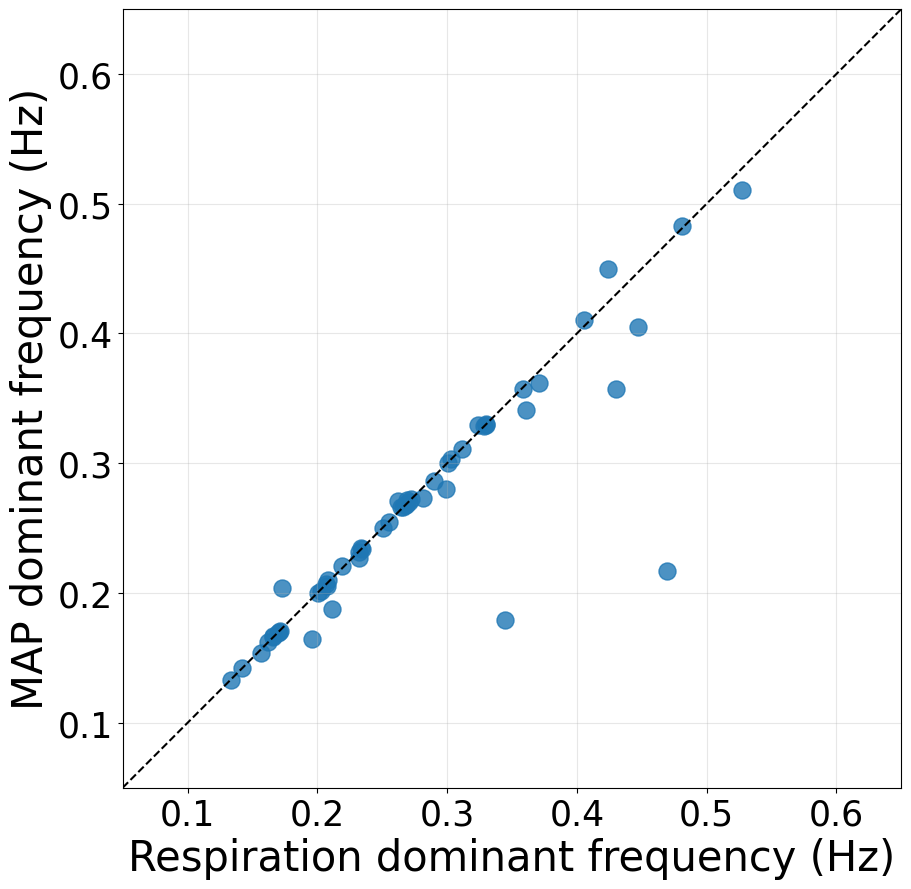

Number of subjects: 54
Spearman rho: 0.906
p-value: 5.03518e-21


In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from joblib import Parallel, delayed
from scipy.signal import (
    butter,
    detrend,
    find_peaks,
    peak_prominences,
    sosfiltfilt,
    welch,
)
from scipy.stats import spearmanr
from tqdm import tqdm

fs = 125                                # Sampling frequency
RESP_FREQ_RANGE = (0.1, 0.6)            # Respiration frequency range in Hz
MAX_DURATION_SEC = 3000                 # Maximum duration of the signal to analyze in seconds
N = int(MAX_DURATION_SEC * fs)          # Maximum number of samples to analyze
ANALYSIS_WINDOW_SEC = 120               # Window length for analysis in seconds
ANALYSIS_OVERLAP = 0.5                  # Overlap fraction for analysis windows
PSD_WINDOW_SEC = 60                     # Window length for PSD calculation in seconds
PSD_OVERLAP = 0.5                       # Overlap fraction for PSD calculation
MIN_PEAK_PROMINENCE_DB = 3.0            # Minimum peak prominence in dB for valid peaks
MIN_VALID_WINDOWS = 5                   # Minimum number of valid windows required for subject-level analysis
FREQUENCY_TOLERANCE = 0.02              # Tolerance for agreement between respiration and MAP dominant frequencies in Hz

data_dir = '../../../../../../data/physionet.org/files/mimicdb/1.0.0'
env_dir = '../results/envelopes'
fig_dir = '../figures'
os.makedirs(fig_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)
files = sorted(os.listdir(env_dir))
subjects = [file.split('.')[0] for file in files if file.endswith('.npz')]

def interpolate_nan(x):
    """
    Interpolate NaN values in a 1D array using linear interpolation used for respiration signal.
    """
    x = np.asarray(x, dtype=float).reshape(-1)
    valid = np.isfinite(x)
    if valid.sum() < 2:
        return None
    if np.all(valid):
        return x
    return np.interp(np.arange(len(x)), np.flatnonzero(valid), x[valid])


sos = butter(4, RESP_FREQ_RANGE, btype='bandpass', fs=fs, output='sos')
# Match SciPy's default SOS padding requirement explicitly.
FILTER_PADLEN = 3 * (2 * len(sos) + 1 - min(
    (sos[:, 2] == 0).sum(), (sos[:, 5] == 0).sum()))
def preprocess_signal(x):
    """
    Interpolate + detrending + bandpass filtering of the input signal.
    """
    x = interpolate_nan(x)
    if x is None or len(x) <= FILTER_PADLEN:
        return None
    x = detrend(x, type='linear')
    x = sosfiltfilt(sos, x, padlen=FILTER_PADLEN)
    return x

def parabolic_peak_frequency(freqs, psd, peak_index):
    """
    Refine the frequency of a PSD peak using parabolic interpolation.

    A parabola is fitted locally to the log-PSD values at the peak and its
    two neighboring frequency bins. The vertex of the parabola provides a
    sub-bin estimate of the peak frequency.
    """
    if peak_index <= 0 or peak_index >= len(psd) - 1:
        return freqs[peak_index]

    log_psd = np.log(psd + np.finfo(float).eps)
    y_left = log_psd[peak_index - 1]
    y_center = log_psd[peak_index]
    y_right = log_psd[peak_index + 1]

    denominator = y_left - 2 * y_center + y_right

    if abs(denominator) <= np.finfo(float).eps:
        return freqs[peak_index]

    offset = 0.5 * (y_left - y_right) / denominator
    offset = np.clip(offset, -0.5, 0.5)
    frequency_step = freqs[1] - freqs[0]

    return freqs[peak_index] + offset * frequency_step


def estimate_dominant_frequency(x):
    """
    Estimate the dominant frequency of a signal within the respiratory frequency band.

    The power spectral density (PSD) is estimated using Welch's method. Peaks within
    the respiratory frequency range are identified, and the peak with the highest
    PSD is selected. The peak is accepted if its prominence exceeds the specified
    minimum threshold, and its frequency is refined using parabolic interpolation.
    """
    x = np.asarray(x, dtype=float).squeeze()

    requested_nperseg = int(PSD_WINDOW_SEC * fs)
    nperseg = min(requested_nperseg, len(x))
    noverlap = min(int(PSD_OVERLAP * nperseg), nperseg - 1)
    nfft = 2 ** int(np.ceil(np.log2(nperseg)))

    freqs, psd = welch(x, fs=fs, window='hann', nperseg=nperseg, noverlap=noverlap, nfft=nfft, detrend='linear', return_onesided=True, scaling='density', average='mean')

    band_mask = (freqs >= RESP_FREQ_RANGE[0]) & (freqs <= RESP_FREQ_RANGE[1])
    freqs_band = freqs[band_mask]
    psd_band = psd[band_mask]

    if len(freqs_band) < 3 or not np.all(np.isfinite(psd_band)) or np.max(psd_band) <= 0:
        return np.nan, np.nan, freqs_band, psd_band

    psd_db = 10 * np.log10(psd_band + np.finfo(float).eps)
    peaks, _ = find_peaks(psd_db)

    if len(peaks) == 0:
        return np.nan, np.nan, freqs_band, psd_band

    prominences_db = peak_prominences(psd_db, peaks)[0]
    strongest_peak_position = np.argmax(psd_band[peaks])
    strongest_peak_index = peaks[strongest_peak_position]
    prominence_db = prominences_db[strongest_peak_position]

    if prominence_db < MIN_PEAK_PROMINENCE_DB:
        return np.nan, prominence_db, freqs_band, psd_band

    dominant_frequency = parabolic_peak_frequency(freqs_band, psd_band, strongest_peak_index)

    return dominant_frequency, prominence_db, freqs_band, psd_band

def estimate_windowed_frequencies(resp, mp):
    """
    Estimate dominant frequencies of respiration and mean arterial pressure (MAP)
    over overlapping analysis windows.

    Both signals are divided into fixed-length overlapping windows. Within each
    window, the dominant frequency and corresponding peak prominence are estimated
    independently for respiration and MAP.
    """
    window_length = int(ANALYSIS_WINDOW_SEC * fs)
    step = max(int(window_length * (1.0 - ANALYSIS_OVERLAP)), 1)
    signal_length = min(len(resp), len(mp))
    window_results = []

    for start in range(0, signal_length - window_length + 1, step):
        stop = start + window_length

        dominant_freq_resp, prominence_resp, _, _ = estimate_dominant_frequency(resp[start:stop])
        dominant_freq_mp, prominence_mp, _, _ = estimate_dominant_frequency(mp[start:stop])

        window_results.append({
            'start_time_sec': start / fs,
            'center_time_sec': (start + stop) / (2 * fs),
            'stop_time_sec': stop / fs,
            'dominant_freq_resp': dominant_freq_resp,
            'dominant_freq_mp': dominant_freq_mp,
            'prominence_resp_db': prominence_resp,
            'prominence_mp_db': prominence_mp
        })

    return pd.DataFrame(window_results)

def aggregate_paired_windows(window_df):
    """
    Aggregate paired respiration and MAP dominant-frequency estimates across windows
    using median.

    Windows with valid dominant-frequency estimates for both respiration and MAP are
    retained. If the number of valid paired windows meets the minimum requirement,
    subject-level frequency estimates and agreement metrics are computed across the
    retained windows.
    """
    paired_valid = np.isfinite(window_df['dominant_freq_resp']) & np.isfinite(window_df['dominant_freq_mp'])
    paired_df = window_df.loc[paired_valid].copy()
    n_valid = len(paired_df)

    if n_valid < MIN_VALID_WINDOWS:
        return {
            'dominant_freq_resp': np.nan,
            'dominant_freq_mp': np.nan,
            'median_freq_difference': np.nan,
            'median_abs_freq_difference': np.nan,
            'agreement_fraction': np.nan,
            'n_valid_windows': n_valid
        }

    resp_freq = paired_df['dominant_freq_resp'].to_numpy()
    mp_freq = paired_df['dominant_freq_mp'].to_numpy()
    differences = mp_freq - resp_freq

    return {
        'dominant_freq_resp': np.median(resp_freq),
        'dominant_freq_mp': np.median(mp_freq),
        'median_freq_difference': np.median(differences),
        'median_abs_freq_difference': np.median(np.abs(differences)),
        'agreement_fraction': np.mean(np.abs(differences) <= FREQUENCY_TOLERANCE),
        'n_valid_windows': n_valid
    }

def process_subject(subject):
    print(f'Processing subject {subject} ...')
    path = f'{data_dir}/{subject}/{subject}'
    signal_values, metadata = wfdb.rdsamp(path, sampto=N)
    channel_names = metadata['sig_name']
    if 'RESP' not in channel_names:
        print(f'Subject {subject}: RESP channel not found.')
        return None
    resp_channel = channel_names.index('RESP')
    resp_raw = signal_values[:, resp_channel]

    path = f'{env_dir}/{subject}.npz'
    data = np.load(path)
    env_u_raw = data['env_u'][:N]
    env_d_raw = data['env_d'][:N]

    n_samples = min(len(resp_raw), len(env_u_raw), len(env_d_raw), N)
    resp_raw = resp_raw[:n_samples]
    env_u_raw = env_u_raw[:n_samples]
    env_d_raw = env_d_raw[:n_samples]

    # MP is derived from the upper and lower envelopes.
    mp_raw = (env_u_raw + env_d_raw) / 2.0

    resp = preprocess_signal(resp_raw)
    mp = preprocess_signal(mp_raw)

    if resp is None or mp is None:
        print(f'Subject {subject}: preprocessing failed.')
        return None

    window_df = estimate_windowed_frequencies(resp, mp)

    if window_df.empty:
        print(f'Subject {subject}: no analysis windows.')
        return None

    subject_result = aggregate_paired_windows(window_df)

    if subject_result['n_valid_windows'] < MIN_VALID_WINDOWS:
        print(f'Subject {subject}: only {subject_result["n_valid_windows"]} valid windows.')
        return None

    result = {
        'subject': subject,
        'dominant_freq_resp': subject_result['dominant_freq_resp'],
        'dominant_freq_mp': subject_result['dominant_freq_mp'],
        'median_freq_difference': subject_result['median_freq_difference'],
        'median_abs_freq_difference': subject_result['median_abs_freq_difference'],
        'agreement_fraction': subject_result['agreement_fraction'],
        'n_valid_windows': subject_result['n_valid_windows']
    }

    print(f'Subject {subject} processed with {subject_result["n_valid_windows"]} valid windows.')

    return result

results = Parallel(n_jobs=-1)(delayed(process_subject)(subject) for subject in tqdm(subjects, desc='Processing subjects'))
results = [result for result in results if result is not None]
if not results:
    raise SystemExit('No subjects had enough valid paired windows; no plot was generated.')
results_df = pd.DataFrame(results)

#%%
# =============================================================================
# Plotting settings
# =============================================================================

FIG_SIZE = (9.5, 9)
MARKER_SIZE = 150
MARKER_ALPHA = 0.8
XLABEL_FONT_SIZE = 30
YLABEL_FONT_SIZE = 30
XTICK_FONT_SIZE = 25
YTICK_FONT_SIZE = 25
IDENTITY_LINE_COLOR = 'black'
IDENTITY_LINE_WIDTH = 1.5
IDENTITY_LINE_STYLE = '--'
GRID_ALPHA = 0.3
AXIS_MIN = 0.05
AXIS_MAX = 0.65
AXIS_TICKS = np.arange(0.1, 0.61, 0.1)

x = results_df['dominant_freq_resp'].to_numpy(dtype=float)
y = results_df['dominant_freq_mp'].to_numpy(dtype=float)

fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.scatter(x, y, s=MARKER_SIZE, alpha=MARKER_ALPHA)

ax.plot([AXIS_MIN, AXIS_MAX], [AXIS_MIN, AXIS_MAX], color=IDENTITY_LINE_COLOR, linestyle=IDENTITY_LINE_STYLE, linewidth=IDENTITY_LINE_WIDTH)

ax.set_xlabel('Respiration dominant frequency (Hz)', fontsize=XLABEL_FONT_SIZE)
ax.set_ylabel('MAP dominant frequency (Hz)', fontsize=YLABEL_FONT_SIZE)

ax.set_xlim(AXIS_MIN, AXIS_MAX)
ax.set_ylim(AXIS_MIN, AXIS_MAX)
ax.set_xticks(AXIS_TICKS)
ax.set_yticks(AXIS_TICKS)

ax.tick_params(axis='x', labelsize=XTICK_FONT_SIZE)
ax.tick_params(axis='y', labelsize=YTICK_FONT_SIZE)
ax.grid(alpha=GRID_ALPHA)
ax.set_aspect('equal', adjustable='box')

plt.tight_layout(rect=[0.05, 0, 1, 1])
path = f'{fig_dir}/scatter.png'
plt.savefig(path, dpi=300)
plt.show()

#%%
resp_freq = results_df['dominant_freq_resp'].to_numpy(dtype=float)
map_freq = results_df['dominant_freq_mp'].to_numpy(dtype=float)

valid = np.isfinite(resp_freq) & np.isfinite(map_freq)
resp_freq = resp_freq[valid]
map_freq = map_freq[valid]

if len(resp_freq) >= 3:
    rho, p_value = spearmanr(resp_freq, map_freq)

    print(f'Number of subjects: {len(resp_freq)}')
    print(f'Spearman rho: {rho:.3f}')
    print(f'p-value: {p_value:.6g}')
else:
    print('Insufficient valid subjects for Spearman correlation.')